In [1]:
import pandas as pd

In [2]:
orders = pd.read_csv('https://raw.githubusercontent.com/suraiyabinteakbar/food-delivery-analytics-and-demand-forecasting/main/data/sample_orders.csv')
orders.head()

,Order ID,Order Date,Restaurant Branch ID,Restaurant Name,Customer ID,Rider ID,Order Status,Order Type,Total Amount,Branch Zone,...,Discount Amount,Promo Code,Restaurant Commission,Platform Subsidy,Restaurant Subsidy Share,Rider Earning,Avg Delivery Time Min,Delivery Status,Month Name,Date
0,ORD100000,2026-02-01 11:27:46,10206,Sushi Circle - Lakeside,CUST06558,RDR-0365,delivered,delivery,1061.75,Lakeside,...,100,WELCOME10,265.44,0.00,0.00,40,22,True,February,2026-02-01
1,ORD100001,2026-05-06 16:40:08,10128,Charcoal Chicken House - Stadium Area,CUST00439,RDR-0184,delivered,delivery,1369.59,Stadium Area,...,100,NaN,272.55,0.00,0.00,80,46,True,May,2026-05-06
2,ORD100002,2026-04-30 11:42:31,10405,Rolls & Wraps Co - Cultural Quarter,CUST08956,RDR-0019,delivered,pickup,259.15,Cultural Quarter,...,100,WELCOME10,55.98,0.00,0.00,70,44,True,April,2026-04-30
3,ORD100003,2026-01-09 10:42:55,10018,The Breakfast Table - Lakeside,CUST05120,RDR-0733,cancelled,delivery,563.55,Lakeside,...,30,WELCOME10,74.95,0.00,0.00,70,50,False,January,2026-01-09
4,ORD100004,2026-02-10 16:25:16,10437,Sushi Circle - Cultural Quarter,CUST05716,RDR-0829,delivered,delivery,306.65,Cultural Quarter,...,0,NaN,75.74,20.53,6.16,70,37,True,February,2026-02-10


In [3]:
print(orders.shape)
print(orders.columns)


(25000, 25)
Index(['Order ID', 'Order Date', 'Restaurant Branch ID', 'Restaurant Name',
       'Customer ID', 'Rider ID', 'Order Status', 'Order Type', 'Total Amount',
       'Branch Zone', 'Delivery Zone', 'Payment Method', 'Payment Gateway',
       'Payment Status', 'Delivery Charge', 'Discount Amount', 'Promo Code',
       'Restaurant Commission', 'Platform Subsidy', 'Restaurant Subsidy Share',
       'Rider Earning', 'Avg Delivery Time Min', 'Delivery Status',
       'Month Name', 'Date'],
      dtype='object')


In [4]:
print(orders['Order Date'].dtype)

object


In [5]:
orders['Order Date'] = pd.to_datetime(orders['Order Date'])
print(orders['Order Date'].dtype)

datetime64[ns]


In [6]:
orders['Hour'] = orders['Order Date'].dt.hour
orders[['Order Date', 'Hour']].head()

,Order Date,Hour
0,2026-02-01 11:27:46,11
1,2026-05-06 16:40:08,16
2,2026-04-30 11:42:31,11
3,2026-01-09 10:42:55,10
4,2026-02-10 16:25:16,16


In [7]:
hourly_counts = orders.groupby('Hour').size()
print(hourly_counts)

Hour
0      178
1      145
2      152
3      176
4      171
5      181
6      327
7      493
8      698
9      918
10     997
11    1799
12    2405
13    1677
14    1007
15     908
16    1047
17    1377
18    1662
19    2386
20    2719
21    2036
22    1065
23     476
dtype: int64


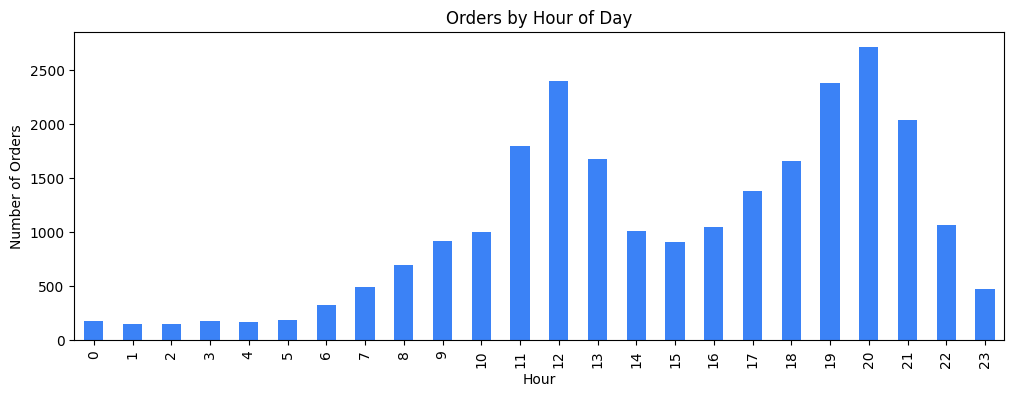

In [8]:
import matplotlib.pyplot as plt

hourly_counts.plot(kind='bar', figsize=(12,4), color='#3b82f6', title='Orders by Hour of Day')
plt.xlabel('Hour')
plt.ylabel('Number of Orders')
plt.show()

In [9]:
orders['Weekday'] = orders['Order Date'].dt.day_name()
weekday_counts = orders.groupby('Weekday').size()
print(weekday_counts)

Weekday
Friday       3654
Monday       3479
Saturday     3547
Sunday       3620
Thursday     3675
Tuesday      3466
Wednesday    3559
dtype: int64


In [10]:
orders['DateHour'] = orders['Order Date'].dt.floor('h')
raw_hourly_counts = orders.groupby('DateHour').size().reset_index(name='OrderCount')

full_hours = pd.date_range(orders['Order Date'].min().floor('h'), orders['Order Date'].max().floor('h'), freq='h')
hourly_series = pd.DataFrame({'DateHour': full_hours}).merge(raw_hourly_counts, on='DateHour', how='left')
hourly_series['OrderCount'] = hourly_series['OrderCount'].fillna(0).astype(int)
hourly_series.head(10)

,DateHour,OrderCount
0,2026-01-01 00:00:00,1
1,2026-01-01 01:00:00,0
2,2026-01-01 02:00:00,0
3,2026-01-01 03:00:00,2
4,2026-01-01 04:00:00,2
5,2026-01-01 05:00:00,2
6,2026-01-01 06:00:00,4
7,2026-01-01 07:00:00,4
8,2026-01-01 08:00:00,5
9,2026-01-01 09:00:00,10


In [11]:
hourly_series['Hour'] = hourly_series['DateHour'].dt.hour
hourly_series['Weekday'] = hourly_series['DateHour'].dt.dayofweek
hourly_series['IsWeekend'] = hourly_series['Weekday'].isin([5, 6]).astype(int)
hourly_series.head(10)


,DateHour,OrderCount,Hour,Weekday,IsWeekend
0,2026-01-01 00:00:00,1,0,3,0
1,2026-01-01 01:00:00,0,1,3,0
2,2026-01-01 02:00:00,0,2,3,0
3,2026-01-01 03:00:00,2,3,3,0
4,2026-01-01 04:00:00,2,4,3,0
5,2026-01-01 05:00:00,2,5,3,0
6,2026-01-01 06:00:00,4,6,3,0
7,2026-01-01 07:00:00,4,7,3,0
8,2026-01-01 08:00:00,5,8,3,0
9,2026-01-01 09:00:00,10,9,3,0


In [12]:
hourly_series = hourly_series.sort_values('DateHour').reset_index(drop=True)

hourly_series['Lag_1h'] = hourly_series['OrderCount'].shift(1)
hourly_series['Lag_24h'] = hourly_series['OrderCount'].shift(24)
hourly_series[['DateHour','OrderCount','Lag_1h','Lag_24h']].head(30)

,DateHour,OrderCount,Lag_1h,Lag_24h
0,2026-01-01 00:00:00,1,NaN,NaN
1,2026-01-01 01:00:00,0,1.0,NaN
2,2026-01-01 02:00:00,0,0.0,NaN
3,2026-01-01 03:00:00,2,0.0,NaN
4,2026-01-01 04:00:00,2,2.0,NaN
5,2026-01-01 05:00:00,2,2.0,NaN
6,2026-01-01 06:00:00,4,2.0,NaN
7,2026-01-01 07:00:00,4,4.0,NaN
8,2026-01-01 08:00:00,5,4.0,NaN
9,2026-01-01 09:00:00,10,5.0,NaN


In [13]:
hourly_series = hourly_series.sort_values('DateHour').reset_index(drop=True)
hourly_clean = hourly_series.dropna(subset=['Lag_1h', 'Lag_24h']).reset_index(drop=True)
print("Rows after dropping NaN:", hourly_clean.shape[0])

Rows after dropping NaN: 3600


In [14]:
split_date = hourly_clean['DateHour'].quantile(0.8, interpolation='nearest')
train = hourly_clean[hourly_clean['DateHour'] <= split_date]
test = hourly_clean[hourly_clean['DateHour'] > split_date]
print("Train:", train.shape[0], "Test:", test.shape[0])

Train: 2880 Test: 720


In [15]:
from sklearn.metrics import mean_absolute_error

baseline_predictions = test['Lag_24h']
baseline_mae = mean_absolute_error(test['OrderCount'], baseline_predictions)
print("Baseline MAE:", baseline_mae)

Baseline MAE: 2.5319444444444446


In [16]:
from sklearn.ensemble import RandomForestRegressor

feature_cols = ['Hour', 'Weekday', 'IsWeekend', 'Lag_1h', 'Lag_24h']
X_train, y_train = train[feature_cols], train['OrderCount']
X_test, y_test = test[feature_cols], test['OrderCount']

model_hourly = RandomForestRegressor(n_estimators=100, random_state=42)
model_hourly.fit(X_train, y_train)

preds_hourly = model_hourly.predict(X_test)
model_mae_hourly = mean_absolute_error(y_test, preds_hourly)

print("Baseline MAE:", baseline_mae)
print("Random Forest MAE:", model_mae_hourly)

Baseline MAE: 2.5319444444444446
Random Forest MAE: 2.0796899659243717


In [17]:
importances_hourly = pd.Series(model_hourly.feature_importances_, index=feature_cols).sort_values(ascending=False)
print(importances_hourly)

Lag_24h      0.628699
Hour         0.234619
Lag_1h       0.080427
Weekday      0.050454
IsWeekend    0.005800
dtype: float64


In [18]:
results_hourly = test[['DateHour', 'OrderCount']].copy()
results_hourly['Predicted'] = preds_hourly
results_hourly['AbsError'] = (results_hourly['OrderCount'] - results_hourly['Predicted']).abs()

print("Largest errors:")
print(results_hourly.sort_values('AbsError', ascending=False).head(10))

Largest errors:
                DateHour  OrderCount  Predicted   AbsError
3356 2026-05-21 20:00:00          27  11.211429  15.788571
3380 2026-05-22 20:00:00          31  17.060000  13.940000
3164 2026-05-13 20:00:00          10  20.999500  10.999500
2888 2026-05-02 08:00:00          14   3.032381  10.967619
2948 2026-05-04 20:00:00          11  21.055667  10.055667
3284 2026-05-18 20:00:00          11  20.854333   9.854333
3348 2026-05-21 12:00:00           9  18.050000   9.050000
2988 2026-05-06 12:00:00          25  16.140000   8.860000
3210 2026-05-15 18:00:00           7  15.760000   8.760000
3309 2026-05-19 21:00:00          10  18.730750   8.730750


In [19]:

all_order_dates = pd.Series(sorted(orders['Order Date'].dt.date.unique()))
split_date = pd.Timestamp(all_order_dates.iloc[int(len(all_order_dates) * 0.8)])
print("Split date (used for both top-10 selection and train/test split):", split_date)
top10_restaurants = (
    orders.loc[orders['Order Date'] < split_date + pd.Timedelta(days=1), 'Restaurant Branch ID']
    .value_counts()
    .head(10)
    .index.tolist()
)
print(top10_restaurants)

sub = orders[orders['Restaurant Branch ID'].isin(top10_restaurants)].copy()
print(sub.shape)

Split date (used for both top-10 selection and train/test split): 2026-05-01 00:00:00
[10279, 10354, 10055, 10289, 10252, 10096, 10019, 10123, 10382, 10263]
(697, 28)


In [20]:
sub['Date'] = sub['Order Date'].dt.date
daily_counts = sub.groupby(['Restaurant Branch ID', 'Date']).size().reset_index(name='OrderCount')
daily_counts.head(10)

,Restaurant Branch ID,Date,OrderCount
0,10019,2026-01-01,3
1,10019,2026-01-07,2
2,10019,2026-01-09,1
3,10019,2026-01-17,1
4,10019,2026-01-19,1
5,10019,2026-01-20,1
6,10019,2026-01-22,1
7,10019,2026-01-26,1
8,10019,2026-01-27,1
9,10019,2026-01-28,2


In [21]:
all_dates = pd.date_range(orders['Order Date'].min().date(), orders['Order Date'].max().date(), freq='D').date

full_grid = pd.MultiIndex.from_product(
    [top10_restaurants, all_dates],
    names=['Restaurant Branch ID', 'Date']
).to_frame(index=False)

daily_full = full_grid.merge(daily_counts, on=['Restaurant Branch ID', 'Date'], how='left')
daily_full['OrderCount'] = daily_full['OrderCount'].fillna(0).astype(int)

print(daily_full.shape)
daily_full.head(10)

(1510, 3)


,Restaurant Branch ID,Date,OrderCount
0,10279,2026-01-01,0
1,10279,2026-01-02,0
2,10279,2026-01-03,0
3,10279,2026-01-04,0
4,10279,2026-01-05,0
5,10279,2026-01-06,0
6,10279,2026-01-07,0
7,10279,2026-01-08,0
8,10279,2026-01-09,0
9,10279,2026-01-10,0


In [22]:
daily_full['Date'] = pd.to_datetime(daily_full['Date'])
daily_full['Weekday'] = daily_full['Date'].dt.dayofweek
daily_full['IsWeekend'] = daily_full['Weekday'].isin([5, 6]).astype(int)
daily_full.head(10)

,Restaurant Branch ID,Date,OrderCount,Weekday,IsWeekend
0,10279,2026-01-01,0,3,0
1,10279,2026-01-02,0,4,0
2,10279,2026-01-03,0,5,1
3,10279,2026-01-04,0,6,1
4,10279,2026-01-05,0,0,0
5,10279,2026-01-06,0,1,0
6,10279,2026-01-07,0,2,0
7,10279,2026-01-08,0,3,0
8,10279,2026-01-09,0,4,0
9,10279,2026-01-10,0,5,1


In [23]:
daily_full = daily_full.sort_values(['Restaurant Branch ID', 'Date']).reset_index(drop=True)

daily_full['Lag_1day'] = daily_full.groupby('Restaurant Branch ID')['OrderCount'].shift(1)
daily_full['Lag_7day'] = daily_full.groupby('Restaurant Branch ID')['OrderCount'].shift(7)

daily_full[['Restaurant Branch ID','Date','OrderCount','Lag_1day','Lag_7day']].head(20)

,Restaurant Branch ID,Date,OrderCount,Lag_1day,Lag_7day
0,10019,2026-01-01,3,NaN,NaN
1,10019,2026-01-02,0,3.0,NaN
2,10019,2026-01-03,0,0.0,NaN
3,10019,2026-01-04,0,0.0,NaN
4,10019,2026-01-05,0,0.0,NaN
5,10019,2026-01-06,0,0.0,NaN
6,10019,2026-01-07,2,0.0,NaN
7,10019,2026-01-08,0,2.0,3.0
8,10019,2026-01-09,1,0.0,0.0
9,10019,2026-01-10,0,1.0,0.0


In [24]:

daily_full['Rolling_7day_avg'] = (
    daily_full
    .groupby('Restaurant Branch ID')['OrderCount']
    .transform(lambda x: x.shift(1).rolling(window=7).mean())
)
daily_full[['Restaurant Branch ID','Date','OrderCount','Lag_1day','Lag_7day','Rolling_7day_avg']].head(20)

,Restaurant Branch ID,Date,OrderCount,Lag_1day,Lag_7day,Rolling_7day_avg
0,10019,2026-01-01,3,NaN,NaN,NaN
1,10019,2026-01-02,0,3.0,NaN,NaN
2,10019,2026-01-03,0,0.0,NaN,NaN
3,10019,2026-01-04,0,0.0,NaN,NaN
4,10019,2026-01-05,0,0.0,NaN,NaN
5,10019,2026-01-06,0,0.0,NaN,NaN
6,10019,2026-01-07,2,0.0,NaN,NaN
7,10019,2026-01-08,0,2.0,3.0,0.714286
8,10019,2026-01-09,1,0.0,0.0,0.285714
9,10019,2026-01-10,0,1.0,0.0,0.428571


In [25]:
print("Rows before dropping NaNs:", daily_full.shape[0])
daily_full_clean = daily_full.dropna(subset=['Lag_1day', 'Lag_7day', 'Rolling_7day_avg']).reset_index(drop=True)
print("Rows after dropping NaNs:", daily_full_clean.shape[0])

Rows before dropping NaNs: 1510
Rows after dropping NaNs: 1440


In [26]:
restaurants = pd.read_csv('https://raw.githubusercontent.com/suraiyabinteakbar/food-delivery-analytics-and-demand-forecasting/main/data/sample_restaurant_master.csv')

daily_full_clean = daily_full_clean.merge(
    restaurants[['restaurant_branch_id', 'restaurant_branch_name', 'city_name', 'commission_pct']],
    left_on='Restaurant Branch ID',
    right_on='restaurant_branch_id',
    how='left'
)

daily_full_clean[['Restaurant Branch ID','restaurant_branch_name','city_name','commission_pct']].drop_duplicates()

,Restaurant Branch ID,restaurant_branch_name,city_name,commission_pct
0,10019,Pasta Palace - Market Square,Rivermouth,20.2
144,10055,Grand Biryani House - Harbor District,Rivermouth,23.9
288,10096,Royal Kebab House - Airport Road,Eastport,16.0
432,10123,Sushi Circle - Business Bay,Eastport,12.6
576,10252,Crispy Bucket Chicken - Hill Gardens,Hillcrest,18.3
720,10263,Pasta Palace - Uptown,Rivermouth,18.6
864,10279,Spice Route Kitchen - Riverside,Rivermouth,17.9
1008,10289,Smokehouse BBQ - University Area,Northgate,19.6
1152,10354,Charcoal Chicken House - Hill Gardens,Hillcrest,23.3
1296,10382,Coastal Seafood Grill - University Area,Northgate,22.3


In [27]:
sub['UsedPromo'] = sub['Promo Code'].notna() & (sub['Promo Code'] != '')
promo_daily = sub.groupby(['Restaurant Branch ID', 'Date'])['UsedPromo'].mean().reset_index(name='PromoUsageRate')
promo_daily['Date'] = pd.to_datetime(promo_daily['Date'])

daily_full_clean = daily_full_clean.merge(promo_daily, on=['Restaurant Branch ID','Date'], how='left')
daily_full_clean['PromoUsageRate'] = daily_full_clean['PromoUsageRate'].fillna(0)

daily_full_clean[['Restaurant Branch ID','Date','OrderCount','PromoUsageRate']].head(10)

,Restaurant Branch ID,Date,OrderCount,PromoUsageRate
0,10019,2026-01-08,0,0.0
1,10019,2026-01-09,1,1.0
2,10019,2026-01-10,0,0.0
3,10019,2026-01-11,0,0.0
4,10019,2026-01-12,0,0.0
5,10019,2026-01-13,0,0.0
6,10019,2026-01-14,0,0.0
7,10019,2026-01-15,0,0.0
8,10019,2026-01-16,0,0.0
9,10019,2026-01-17,1,0.0


In [28]:
daily_full_clean = daily_full_clean.sort_values(['Restaurant Branch ID', 'Date']).reset_index(drop=True)
daily_full_clean['PromoUsageRate_Lag1'] = daily_full_clean.groupby('Restaurant Branch ID')['PromoUsageRate'].shift(1)
daily_full_clean['PromoUsageRate_Lag1'] = daily_full_clean['PromoUsageRate_Lag1'].fillna(0)

In [29]:
daily_full_clean = daily_full_clean.sort_values('Date').reset_index(drop=True)
train = daily_full_clean[daily_full_clean['Date'] <= split_date]
test = daily_full_clean[daily_full_clean['Date'] > split_date]

print("Train rows:", train.shape[0], " | Test rows:", test.shape[0])
print("Train date range:", train['Date'].min(), "to", train['Date'].max())
print("Test date range:", test['Date'].min(), "to", test['Date'].max())

Train rows: 1140  | Test rows: 300
Train date range: 2026-01-08 00:00:00 to 2026-05-01 00:00:00
Test date range: 2026-05-02 00:00:00 to 2026-05-31 00:00:00


In [30]:
from sklearn.metrics import mean_absolute_error

baseline_predictions = test['Lag_7day']
actual_values = test['OrderCount']

baseline_mae = mean_absolute_error(actual_values, baseline_predictions)
print("Baseline MAE:", baseline_mae)

Baseline MAE: 0.54


In [31]:
from sklearn.ensemble import RandomForestRegressor

feature_cols = ['Weekday', 'IsWeekend', 'Lag_1day', 'Lag_7day', 'Rolling_7day_avg', 'commission_pct', 'PromoUsageRate_Lag1']

X_train = train[feature_cols]
y_train = train['OrderCount']

X_test = test[feature_cols]
y_test = test['OrderCount']

model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

print("Model trained.")

Model trained.


In [32]:
model_predictions = model.predict(X_test)
model_mae = mean_absolute_error(y_test, model_predictions)

print("Baseline MAE:", baseline_mae)
print("Random Forest MAE:", model_mae)
print("Improvement:", baseline_mae - model_mae)

Baseline MAE: 0.54
Random Forest MAE: 0.5479682696007696
Improvement: -0.007968269600769573


commission_pct         0.273185
Rolling_7day_avg       0.222888
Weekday                0.215457
Lag_7day               0.116920
Lag_1day               0.090521
PromoUsageRate_Lag1    0.055207
IsWeekend              0.025822
dtype: float64


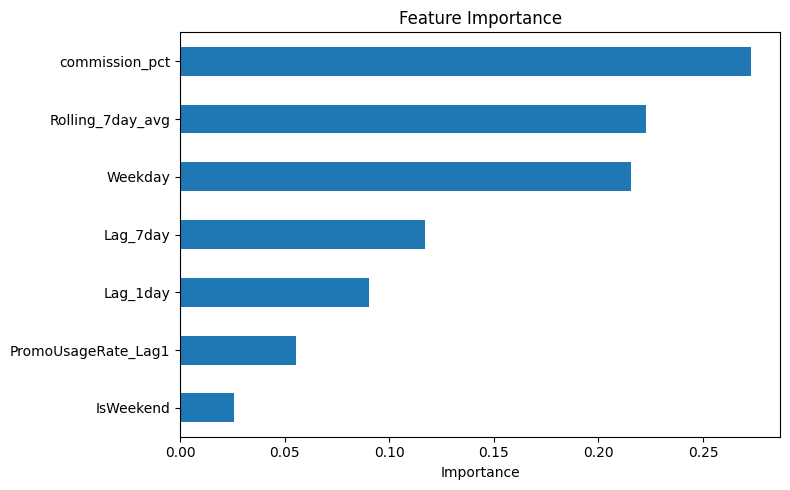

In [33]:
importances = pd.Series(model.feature_importances_, index=feature_cols).sort_values(ascending=False)
print(importances)

importances.plot(kind='barh', figsize=(8,5), title='Feature Importance')
plt.xlabel('Importance')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

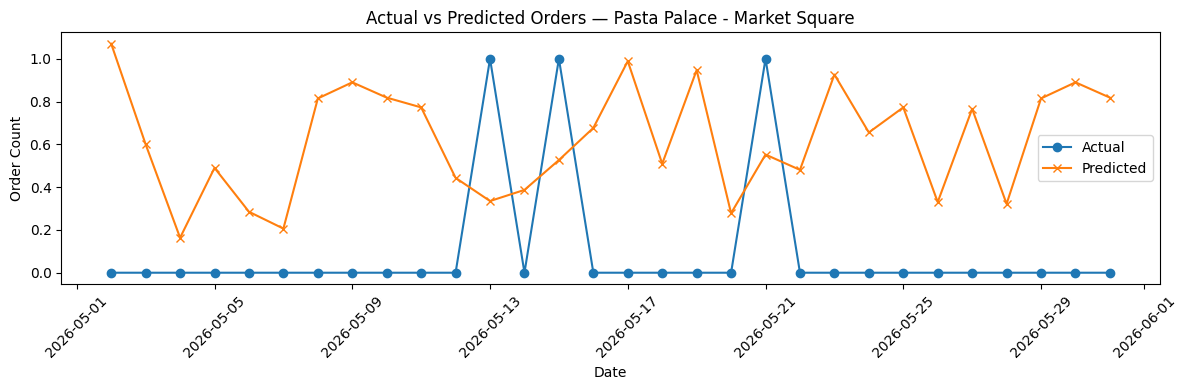

In [34]:
results = test[['Restaurant Branch ID', 'restaurant_branch_name', 'Date', 'OrderCount']].copy()
results['Predicted'] = model_predictions

sample_restaurant_id = results['Restaurant Branch ID'].iloc[0]
sample_restaurant = results['restaurant_branch_name'].iloc[0]
plot_data = results[results['Restaurant Branch ID'] == sample_restaurant_id].sort_values('Date')

plt.figure(figsize=(12,4))
plt.plot(plot_data['Date'], plot_data['OrderCount'], label='Actual', marker='o')
plt.plot(plot_data['Date'], plot_data['Predicted'], label='Predicted', marker='x')
plt.title(f'Actual vs Predicted Orders — {sample_restaurant}')
plt.xlabel('Date')
plt.ylabel('Order Count')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [35]:
results['Error'] = results['OrderCount'] - results['Predicted']
results['AbsError'] = results['Error'].abs()

print("Largest errors (model most wrong):")
print(results.sort_values('AbsError', ascending=False).head(10))

Largest errors (model most wrong):
      Restaurant Branch ID                 restaurant_branch_name       Date  \
1356                 10055  Grand Biryani House - Harbor District 2026-05-23   
1237                 10123            Sushi Circle - Business Bay 2026-05-11   
1234                 10289       Smokehouse BBQ - University Area 2026-05-11   
1223                 10096       Royal Kebab House - Airport Road 2026-05-10   
1409                 10123            Sushi Circle - Business Bay 2026-05-28   
1298                 10055  Grand Biryani House - Harbor District 2026-05-17   
1158                 10354  Charcoal Chicken House - Hill Gardens 2026-05-03   
1388                 10279        Spice Route Kitchen - Riverside 2026-05-26   
1280                 10289       Smokehouse BBQ - University Area 2026-05-16   
1295                 10354  Charcoal Chicken House - Hill Gardens 2026-05-17   

      OrderCount  Predicted     Error  AbsError  
1356           0   3.322833 -3.322

In [36]:
error_by_restaurant = results.groupby('restaurant_branch_name')['AbsError'].mean().sort_values(ascending=False)
print(error_by_restaurant)

restaurant_branch_name
Charcoal Chicken House - Hill Gardens      0.648681
Smokehouse BBQ - University Area           0.629925
Pasta Palace - Market Square               0.623379
Grand Biryani House - Harbor District      0.618407
Crispy Bucket Chicken - Hill Gardens       0.533864
Coastal Seafood Grill - University Area    0.523375
Sushi Circle - Business Bay                0.500512
Royal Kebab House - Airport Road           0.488311
Spice Route Kitchen - Riverside            0.475241
Pasta Palace - Uptown                      0.437989
Name: AbsError, dtype: float64


In [37]:
from sklearn.ensemble import GradientBoostingRegressor

In [38]:
feat_a = ['Hour', 'Weekday', 'IsWeekend', 'Lag_1h', 'Lag_24h']
split_date_a = hourly_clean['DateHour'].quantile(0.8, interpolation='nearest')
train_a = hourly_clean[hourly_clean['DateHour'] <= split_date_a]
test_a = hourly_clean[hourly_clean['DateHour'] > split_date_a]

X_train_a, y_train_a = train_a[feat_a], train_a['OrderCount']
X_test_a, y_test_a = test_a[feat_a], test_a['OrderCount']

gb_model_a = GradientBoostingRegressor(random_state=42)
gb_model_a.fit(X_train_a, y_train_a)
gb_preds_a = gb_model_a.predict(X_test_a)
gb_mae_a = mean_absolute_error(y_test_a, gb_preds_a)

print("Random Forest MAE:", model_mae_hourly)
print("Gradient Boosting MAE:", gb_mae_a)

Random Forest MAE: 2.0796899659243717
Gradient Boosting MAE: 1.8786333419022543


In [39]:
feat_b = ['Weekday', 'IsWeekend', 'Lag_1day', 'Lag_7day', 'Rolling_7day_avg', 'commission_pct', 'PromoUsageRate_Lag1']
print(daily_full_clean[feat_b].isna().sum())

Weekday                0
IsWeekend              0
Lag_1day               0
Lag_7day               0
Rolling_7day_avg       0
commission_pct         0
PromoUsageRate_Lag1    0
dtype: int64


In [40]:
print(daily_full_clean.shape)
print(daily_full_clean[feat_b].isna().sum())

(1440, 14)
Weekday                0
IsWeekend              0
Lag_1day               0
Lag_7day               0
Rolling_7day_avg       0
commission_pct         0
PromoUsageRate_Lag1    0
dtype: int64


In [41]:
feat_b = ['Weekday', 'IsWeekend', 'Lag_1day', 'Lag_7day', 'Rolling_7day_avg', 'commission_pct', 'PromoUsageRate_Lag1']
split_date_b = split_date
train_b = daily_full_clean[daily_full_clean['Date'] <= split_date_b]
test_b = daily_full_clean[daily_full_clean['Date'] > split_date_b]

print("Random Forest test rows:", len(test))
print("Gradient Boosting test rows:", len(test_b))
print("Random Forest test start:", test['Date'].min())
print("Gradient Boosting test start:", test_b['Date'].min())
assert len(test) == len(test_b)
assert test['Date'].reset_index(drop=True).equals(test_b['Date'].reset_index(drop=True))
assert test['Restaurant Branch ID'].reset_index(drop=True).equals(test_b['Restaurant Branch ID'].reset_index(drop=True))
assert test['OrderCount'].reset_index(drop=True).equals(test_b['OrderCount'].reset_index(drop=True))
print("Confirmed: Random Forest and Gradient Boosting are evaluated on the identical test rows, dates, branches, and target values.")

X_train_b, y_train_b = train_b[feat_b], train_b['OrderCount']
X_test_b, y_test_b = test_b[feat_b], test_b['OrderCount']

gb_model_b = GradientBoostingRegressor(random_state=42)
gb_model_b.fit(X_train_b, y_train_b)
gb_preds_b = gb_model_b.predict(X_test_b)
gb_mae_b = mean_absolute_error(y_test_b, gb_preds_b)

print("Random Forest MAE:", model_mae)
print("Gradient Boosting MAE:", gb_mae_b)

Random Forest test rows: 300
Gradient Boosting test rows: 300
Random Forest test start: 2026-05-02 00:00:00
Gradient Boosting test start: 2026-05-02 00:00:00
Confirmed: Random Forest and Gradient Boosting are evaluated on the identical test rows, dates, branches, and target values.
Random Forest MAE: 0.5479682696007696
Gradient Boosting MAE: 0.5336804738437188


# Food Delivery Demand Forecasting Using Machine Learning

## Project Overview

This project explores how historical food delivery order data can be used to predict future demand. I worked on two forecasting tasks: predicting hourly order volume across the entire platform and predicting daily order volume for the ten highest-volume restaurants.

The project started with analyzing ordering patterns and understanding how demand changes over time. I then used these patterns to build forecasting models and compared their predictions with actual order counts.

Since the original company data was confidential, I used a synthetic dataset designed to represent similar food delivery patterns.

## Project Objectives

- Explore order patterns across different hours, weekdays, dates, and restaurants.
- Identify useful features for predicting future order volumes.
- Build baseline forecasting methods for comparison.
- Train and compare Random Forest and Gradient Boosting regression models.
- Evaluate predictions using Mean Absolute Error (MAE).
- Examine prediction errors to understand where and why the models perform poorly.

## Dataset

The dataset contains approximately 25,000 synthetic order records covering 150 days of food delivery activity.

It includes order timestamps, restaurant information, and promotional usage data. These records were used to examine both platform-wide demand and individual restaurant ordering patterns.

## Forecasting Approaches

This project covers two separate forecasting tasks.

**1. Platform-wide Hourly Demand Forecasting**

The first task predicts the total number of orders received across the platform in a particular hour. MAE here is in orders per hour.

I grouped individual order records into hourly intervals and examined how order volume changes throughout the day and across different dates. The resulting dataset was used to train models that predict hourly demand based on historical patterns and time-related features.

**2. Restaurant-Level Daily Demand Forecasting**

The second task predicts the number of orders received by each of the ten highest-volume restaurants, selected using training-period data only, on a particular day. MAE here is in orders per restaurant-day.

During the initial analysis, I found that restaurant-level hourly data was too sparse for meaningful forecasting. Approximately 97.74% of possible restaurant-hour combinations had zero orders. I therefore changed the forecasting interval from hourly to daily and focused on the ten restaurants with the highest order volumes.

## How the models are evaluated

Both tasks use a rolling one-step-ahead setup, not a single forecast made once at the start of the test period. The lag and rolling features (`Lag_1h`, `Lag_24h`, `Lag_1day`, `Lag_7day`, `Rolling_7day_avg`) are built from actual past order counts across the full time series, before the train/test split. So each test-period prediction is allowed to use the real order counts from the periods immediately before it -- a prediction for May 4 at 20:00 can use the actual order count for May 3 at 20:00 (24 hours earlier), and a restaurant's prediction for a given day can use its actual order count from the day before. This is a legitimate forecasting setup if actual counts become available before each new prediction is needed, but it is not the same as forecasting an entire future month using only what was known on day one of the test period. I'm stating this explicitly because it affects how the results should be read.

## Methodology

Both forecasting tasks followed a similar workflow:

1. **Data Exploration:** Examined the dataset, checked its structure, and analyzed order distribution across different time periods and restaurants.
2. **Data Preprocessing:** Converted timestamps into datetime format, handled missing values, and prepared the data for analysis.
3. **Feature Engineering:** Extracted features such as hour of day and day of week. I also created lag features and rolling averages to include information from previous periods.
4. **Train-Test Split:** Used a chronological split, training the models on earlier observations and evaluating them on later observations.
5. **Baseline Forecasting:** Created simple forecasting methods using previous order counts as reference predictions.
6. **Model Training:** Trained Random Forest Regressor and Gradient Boosting Regressor models.
7. **Model Evaluation:** Compared the models against their respective baselines using Mean Absolute Error.
8. **Error Analysis:** Examined actual and predicted order counts, feature importance, and periods with larger prediction errors.

## Models and Evaluation

I used two tree-based regression algorithms:

- **Random Forest Regressor:** Combines predictions from multiple decision trees to estimate order demand.
- **Gradient Boosting Regressor:** Builds decision trees sequentially, with each new tree attempting to reduce the errors made by previous trees.

Mean Absolute Error (MAE) was used to evaluate model performance, in the original order-count units (not normalized). It measures the average absolute difference between predicted and actual order counts, with lower values indicating smaller prediction errors.


## Data Preparation and Evaluation Checks

Several data preparation and evaluation checks were important for making the forecasting comparisons consistent:

1. **Complete hourly timeline:** Included hours with zero orders so that `Lag_24h` consistently refers to the same hour on the previous day.
2. **Restaurant identification:** Used `Restaurant Branch ID` rather than restaurant names for grouping and merging, since different branches can share the same name.
3. **Lag and rolling features:** Calculated lag features and rolling averages before removing rows with insufficient historical data, then used the same cleaned dataset for both models.
4. **Training-period selection:** Selected the ten highest-volume restaurants using training-period data only and applied the same cutoff date to restaurant selection and model evaluation.
5. **Promotional features:** Used the previous day's promotional usage rate to avoid including information from the prediction day.
6. **Consistent evaluation:** Verified that Random Forest and Gradient Boosting were evaluated on identical restaurant-level test observations, dates, branch IDs and target values.



## Results and Observations

| Forecasting task | Baseline MAE | Best ML MAE | Result |
|---|---:|---:|---|
| Platform-wide hourly | 2.53 | 1.88 (Gradient Boosting) | 26% improvement |
| Restaurant-level daily | 0.54 | 0.53 (Gradient Boosting) | 1.2% improvement |

For Platform-wide hourly forecasting, Gradient Boosting reduced the mean absolute error by approximately 26% compared with the baseline. Random Forest also performed better than the baseline, but Gradient Boosting achieved the lowest error.

For restaurant-level daily forecasting, Gradient Boosting reduced MAE by approximately 1.2%, while Random Forest performed approximately 1.5% worse than the baseline. Both models were evaluated on the same 300 restaurant-day observations, covering the same restaurants and test period. The small difference between the results does not establish a meaningful advantage over the baseline, particularly given the limited dataset.

**Feature importance and error analysis**

- For Track A, Random Forest identified `Lag_24h` as its most important feature, followed by `Hour`. This suggests that the previous day's demand at the same hour was particularly informative for estimating hourly order volume.
- For Track B, the strongest Random Forest features were `commission_pct`, `Rolling_7day_avg`, and `Weekday`. Since the model performed similarly to the baseline, these feature rankings should be interpreted cautiously.
- The two largest hourly prediction errors from Random Forest occurred on May 21 and May 22. I examined the data generation logic and found no specific events associated with those dates, so the errors may reflect random variation. Track B's largest errors occurred on different dates, including May 23 and May 11, rather than showing a similar pattern across both forecasting tasks.

Feature importance and error analysis are based on Random Forest. Although Gradient Boosting achieved the best hourly forecasting result, these two analyses were not performed on that model.


## Limitations

The project uses synthetic data rather than actual company order records, so the results should not be treated as evidence of real-world forecasting performance.

The models were evaluated using a rolling one-step-ahead setup on a held-out period from the same dataset, not on an independent real-world dataset or a true multi-period-ahead forecast. They also do not account for external factors such as holidays, special events, weather conditions, or unexpected changes in customer behavior.

Because I inspected this test period during iterative data-quality corrections and model comparisons, it should be treated as an exploratory temporal holdout rather than an untouched final benchmark.

The forecasting models estimate expected order volume based on historical patterns. They do not measure the causal effect of promotional campaigns or other business decisions.

For restaurant-level daily forecasting specifically, ten restaurants and roughly five months of data may simply not be enough to show a model advantage over a naive baseline. A larger number of restaurants, a longer time period, or additional features (such as weather or local events) would be a more honest next step than tuning the current models further on this amount of data.

